# 2D Segmentation with the Datamint Trainer API

This notebook shows how to train **DeepLab V3+, UNet++ and TransUNet semantic segmentation** model on the **BUSI** (Breast Ultrasound Images) dataset using Datamint's **Trainer API** — a high-level wrapper that handles dataset loading, model creation, training, experiment tracking, and model registration from a small amount of code.

## Comparison with the manual Workflow

The conventional way requires you to:
1. Define transforms, loss function, metrics, and a full LightningModule (~150 lines)
2. Configure MLflow logger, callbacks, and Trainer (~50 lines)
3. Build and wire together `DatamintDataModule`, `L.Trainer`, etc.

With the Trainer API, **all of that is replaced by ~3 lines**:

```python
from datamint.lightning.trainers import DeepLabV3PlusTrainer

trainer = DeepLabV3PlusTrainer(project='MyProject')
results = trainer.fit()
```

The same applies to the other models.


## What You'll Learn

1. Upload data to Datamint
2. Train with `DeepLabV3PlusTrainer`, `UNetPPTrainer`, `TransUNetTrainer` using **zero configuration**
3. Train with `SemanticSegmentation2DTrainer` while swapping in a custom external model
4. Visualise predictions
5. Register and deploy the trained model

## Required Dependencies

```bash
pip install datamint
```

In [ ]:
from datamint import Api

PROJECT_NAME = "deeplabv3plus_Segmentation_Tutorial"
api = Api()

## 1. Setup: Create Project and Load Dataset

`datamint.examples.busi_dataset` downloads the [BUSI breast-ultrasound dataset](https://www.kaggle.com/datasets/sabahesaraki/breast-ultrasound-images-dataset), uploads the images to a Datamint project (tagged `busi`), and uploads the lesion segmentation masks for the `benign` / `malignant` classes. The call is idempotent — if the project already exists, it's returned as-is without re-uploading.

In [2]:
from datamint.examples import busi_dataset

proj = busi_dataset.create(project_name=PROJECT_NAME, api=api)
proj

BUSI Segmentation Example
  project 'deeplabv3plus_Segmentation_Tutorial' already exists, skipping data population.
  https://app.datamint.io/projects/edit/6f0c4ccb-8dda-41c1-be60-144e4953270c


deeplabv3plus_Segmentation_Tutorial
2026-06-01T12:48:44.168Z
lucasmello.research@gmail.com
False
780


### 1.1 Tag Train/Val/Test Splits

We split the dataset into three subsets using tags for reproducibility.

| Split | Percentage | Purpose |
|-------|------------|---------|
| Train | 70% | Model training |
| Validation | 15% | Hyperparameter tuning, early stopping |
| Test | 15% | Final model evaluation |

In [3]:
import random

all_resources = list(api.resources.get_list(project_name=PROJECT_NAME, tags=['busi']))
all_resources.sort(key=lambda r: r.filename)

random.seed(42)
random.shuffle(all_resources)

n_total = len(all_resources)
n_train = int(0.7 * n_total)
n_val = int(0.15 * n_total)

train_resources = all_resources[:n_train]
val_resources = all_resources[n_train:n_train + n_val]
test_resources = all_resources[n_train + n_val:]

api.projects.assign_splits(train_resources, split_name='train', project=proj)
api.projects.assign_splits(val_resources, split_name='val', project=proj)### 3.1 UNet++
api.projects.assign_splits(test_resources, split_name='test', project=proj)

print(f"Train: {len(train_resources)}, Val: {len(val_resources)}, Test: {len(test_resources)}")

Train: 546, Val: 117, Test: 117


## 2. Training with the Trainer API

This is where the **Trainer API** shines. Instead of manually defining:
- A dataset with the correct flags
- Augmentation pipelines
- A LightningModule with loss, metrics, optimizer
- Callbacks, loggers, and a Lightning Trainer
- A deployment adapter

...you simply create a `UNetPPTrainer`, `DeepLabV3PlusTrainer`, or even a `SemanticSegmentation2DTrainer` and call `fit()`.


If your project contains 3D volumes instead of 2D images, the 2D trainer automatically slices them into 2D samples before training.

The trainer automatically:
1. Builds an `ImageDataset` for 2D projects, or a sliced 2D view of a volume dataset when the project is volumetric
2. Creates augmentation pipelines (with medical-image-specific augmentations for `UNetPPTrainer` (`DeepLabV3PlusTrainer`))
3. Instantiates a default segmentation model when `model=None`
4. Sets up **BCE + Dice loss**, **IoU** and **Dice** metrics
5. Configures MLflow logging, checkpointing, and early stopping
6. Trains and evaluates on the test split.

Here you can choose between two options, DeepLabV3 or UNet++:

### 3.1.1 DeepLabV3

In [3]:
from datamint.lightning import DeepLabV3PlusTrainer

trainer = DeepLabV3PlusTrainer(
    project=PROJECT_NAME,
    image_size=256,
    batch_size=16,
    max_epochs=2,
    accelerator='auto',
    # model_name='MyModelName' # Default is project name
)

### 3.1.2 UNet++

In [3]:
from datamint.lightning import UNetPPTrainer

trainer = UNetPPTrainer(
    project=PROJECT_NAME,
    image_size=256,
    batch_size=16,
    max_epochs=5,
    accelerator='auto',
    # model_name='MyModelName' # Default is project name
)

### 3.1.3 TransUNetTrainer

In [6]:
from datamint.lightning import TransUNetTrainer

trainer = TransUNetTrainer(
    project=PROJECT_NAME,
    # image_size is omitted — TransUNetTrainer always uses 224×224.
    # Passing any other value raises a ValueError.
    batch_size=16,
    max_epochs=5,
    pretrained=True,   # loads ImageNet-21k pre-trained R50+ViT-B/16 weights
    accelerator='cpu',
)

Then, we just need to train our model.

In [ ]:
results = trainer.fit()

That's it! The entire training pipeline in just a single line.

Let's inspect the results:

In [5]:
print("Test results:")
for metric_dict in results['test_results']:
    for k, v in metric_dict.items():
        print(f"  {k}: {v:.4f}")

Test results:
  test/loss: 1.2529
  test/dice: 0.3120
  test/iou: 0.2403


### 3.1.4 Using a custom or external model

You can keep the Datamint trainer workflow and swap only the model architecture.

There are two supported patterns:
1. (**RECOMMENDED**) Pass a `SegmentationModule` subclass **class** to `model=`. This is the preferred path when you want Datamint to manage computing loss and metrics, and when you want the resulting model to remain Datamint-compatible for inference and deployment. In this case, pass the class, not the instance object.
2. Pass a fully constructed `lightning.LightningModule` **instance** to `model=` when you want complete control over `training_step`, `validation_step`, `test_step`, and `configure_optimizers`.

The example below uses `UNet++` from `segmentation_models_pytorch` as an external architecture while still keeping the Datamint trainer workflow.

In [ ]:
import segmentation_models_pytorch as smp

from datamint.lightning import SemanticSegmentation2DTrainer
from datamint.lightning.trainers.lightning_modules import SegmentationModule


class MyCustomSegModel(SegmentationModule):
    def __init__(self, *args, **kwargs):
        super().__init__(*args,
                         class_names=['benign', 'malignant'],
                         **kwargs)
        self.model = smp.UnetPlusPlus(
            encoder_name="resnet34",
            encoder_weights="imagenet",
            in_channels=3,
            classes=2,
        )  # or load a pretrained model, etc.

    def forward(self, x):
        return self.model(x)

    # OPTIONAL: Override test_step for custom behaviour
    def test_step(self, batch: dict, batch_idx: int):
        # # Optionally override test_step for custom behavior during testing
        # images = batch['image']  # shape: (BatchSize, 3, H, W)
        # masks = batch['masks']  # shape: (BatchSize, NumClasses+1, H, W) # +1 because of the "background" class

        # (...) custom test logic, e.g. compute additional metrics, log images, etc.
        # loss = self.criterion(self(images), masks)
        # custom_metrics = compute_custom_metrics(logits, masks)
        # self.log('test/loss', custom_metrics) # IMPORTANT
        # self.log('test/custom_metric', custom_metrics)
        # (...)

        # For now, just call the default test_step
        return super().test_step(batch, batch_idx)


trainer = SemanticSegmentation2DTrainer(
    project=PROJECT_NAME,
    image_size=256,
    batch_size=16,
    early_stopping_patience=10,
    model=MyCustomSegModel,  # You can also pass an instance of MyCustomSegModel() if you prefer
    accelerator='auto',  # automatically use GPU if available, otherwise CPU
    # model_name='MyModelName' # Default is project name
)

In [ ]:
results = trainer.test(register_model=True) # automatically saves the model into Datamint's server

We can also inspect the results:

In [ ]:
print("Test results:")
for metric_dict in results:
    for k, v in metric_dict.items():
        print(f"  {k}: {v:.4f}")

Getting results after restarting the kernel...

In [ ]:
registered_model = api.models.get_by_name(PROJECT_NAME)
latest_version = registered_model.get_latest_version()

print(f"Metrics for {PROJECT_NAME} v{latest_version.version}:")
for metric_name, value in latest_version.get_metrics().items():
    print(f" - {metric_name}: {value}")

You can always retrieve the trained model instance from the trainer at `trainer.model`.

When the model inherits from `SegmentationModule`, the registered artifact already has Datamint-compatible prediction behaviour.

### 3.2 Local Inference

In [ ]:

from datamint.mlflow import flavors as datamint_flavor

r = trainer.dataset[0]['resource']

model_loaded = datamint_flavor.load_model(f'models:/{PROJECT_NAME}/latest')
model_loaded.predict([r])

### 3.3 Storing Local Inference Predictions

`model.predict()` returns predictions locally — they are not automatically saved. To persist them as annotations in Datamint, use `api.annotations.upload_predictions()`.

In [ ]:
r = trainer.dataset[0]['resource']

predictions_per_resource = model_loaded.predict([r])
api.annotations.upload_predictions(r, predictions_per_resource[0])

## 3. Visualize predictions

Let's visualize the model predictions against ground truth on test samples.

/home/luan/Desktop/Datamint/Codes/datamint-python-api/datamint/env/lib/python3.12/site-packages/albumentations/core/transforms_interface.py:310: UserWarning: The image is already an RGB.
  target_function(ensure_contiguous_output(arg), **params),
/home/luan/Desktop/Datamint/Codes/datamint-python-api/datamint/env/lib/python3.12/site-packages/albumentations/core/transforms_interface.py:310: UserWarning: The image is already an RGB.
  target_function(ensure_contiguous_output(arg), **params),
/home/luan/Desktop/Datamint/Codes/datamint-python-api/datamint/env/lib/python3.12/site-packages/albumentations/core/transforms_interface.py:310: UserWarning: The image is already an RGB.
  target_function(ensure_contiguous_output(arg), **params),


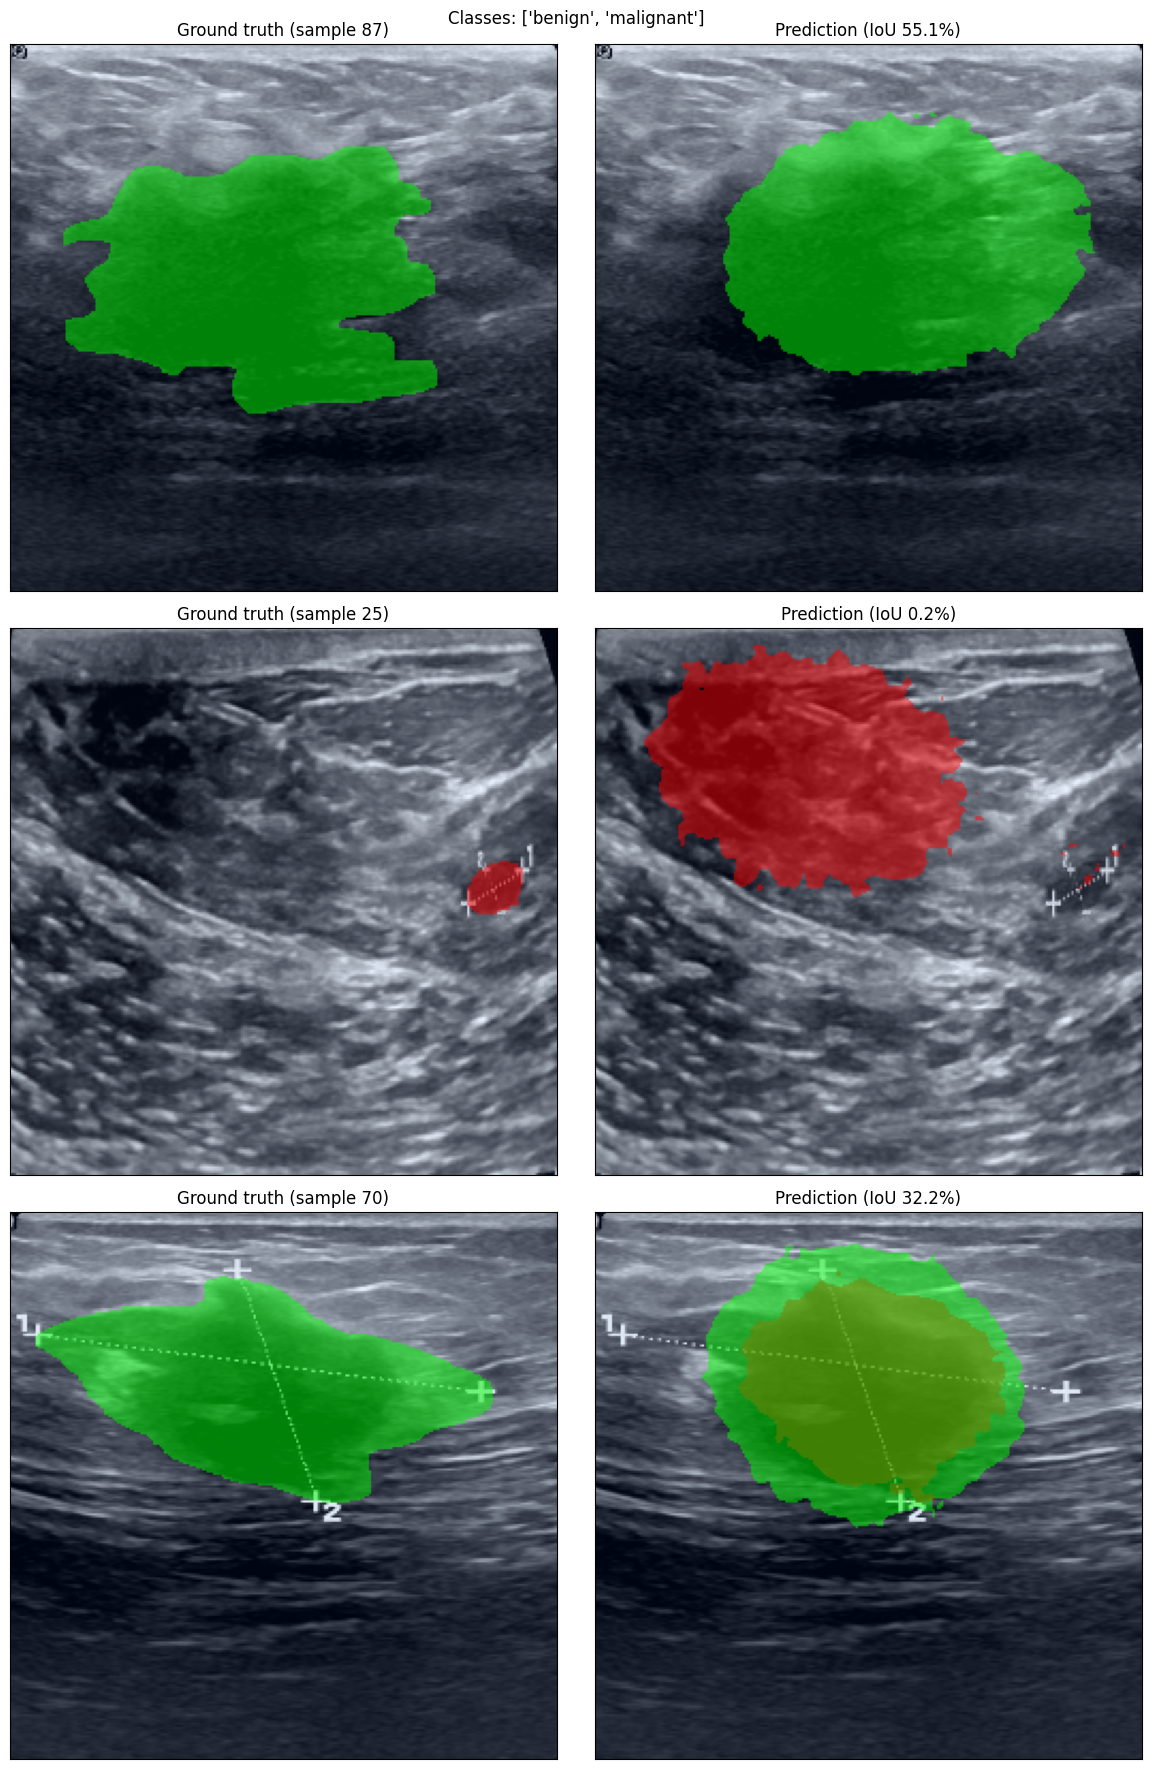

In [12]:
import numpy as np
import torch
from matplotlib import pyplot as plt
from torchmetrics.functional.segmentation import mean_iou

from datamint.utils.visualization import draw_masks, show

model = trainer.model.eval()
test_dataset = trainer.datamodule.test_dataloader().dataset
class_names = trainer.datamodule.dataset.seglabel_list

fig, axes = plt.subplots(3, 2, figsize=(12, 18))
for row, idx in enumerate(np.random.choice(len(test_dataset), 3, replace=False)):
    sample = test_dataset[idx]
    image, mask_gt = sample['image'], sample['masks'][1:]  # drop background channel

    with torch.inference_mode():
        mask_pred = (model(image.unsqueeze(0).to(model.device))[0] > 0).cpu()

    iou = mean_iou(mask_pred[None].long(), mask_gt[None].long(),
                   num_classes=len(class_names), input_format='one-hot')

    show(draw_masks(image, mask_gt, alpha=0.5), ax=axes[row, 0])
    show(draw_masks(image, mask_pred, alpha=0.5), ax=axes[row, 1])
    axes[row, 0].set_title(f'Ground truth (sample {idx})')
    axes[row, 1].set_title(f'Prediction (IoU {iou.item():.1%})')

fig.suptitle(f'Classes: {class_names}')
plt.tight_layout()
plt.show()


## 4. Customization options

The Trainer API is customizable at several layers. Here are the most common overrides:

### 5.1 Change the encoder backbone (example using uNet++)

Use any encoder supported by [segmentation_models_pytorch](https://github.com/qubvel-org/segmentation_models.pytorch):

```python
trainer = UNetPPTrainer(
    project=PROJECT_NAME,
    encoder_name='efficientnet-b4',  # Larger encoder
    image_size=384,                  # Higher resolution
    batch_size=8,                    # Smaller batch for larger model
)
```

### 5.2 Custom transforms and loss

```python
import albumentations as A
from albumentations.pytorch import ToTensorV2

my_transforms = A.Compose([
    A.Resize(512, 512),
    A.CLAHE(p=0.3),
    A.Normalize(),
    ToTensorV2(),
])

trainer = UNetPPTrainer(
    project=PROJECT_NAME,
    train_transform=my_transforms,
    loss_fn=torch.nn.BCEWithLogitsLoss(),
)
```

### 5.3 Pass extra Lightning Trainer arguments

```python
trainer = UNetPPTrainer(
    project=PROJECT_NAME,
    trainer_kwargs={
        'precision': '16-mixed',      # Mixed precision training
        'gradient_clip_val': 1.0,     # Gradient clipping
        'accumulate_grad_batches': 4, # Gradient accumulation
    },
)
```

### 5.4 Custom model arch and Datamint-compatible model

When you want a different architecture but still want the trainer to own the loss, metrics, MLflow model behaviour, and deployment path, subclass `SegmentationModule` and pass the class to `model=`:

```python
from datamint.lightning.trainers.lightning_modules import SegmentationModule
import segmentation_models_pytorch as smp

class MyCustomSegModel(SegmentationModule):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, class_names=['benign', 'malignant'], **kwargs)
        self.model = smp.DeepLabV3Plus(
            encoder_name='resnet50',
            encoder_weights='imagenet',
            in_channels=3,
            classes=2,
        )

    def forward(self, x):
        return self.model(x)

trainer = SemanticSegmentation2DTrainer(
    project=PROJECT_NAME,
    model=MyCustomSegModel,
    image_size=256,
)
```

Passing the class object lets the trainer inject `loss_fn` and `metrics_factories`.

### 5.5 Use a fully custom LightningModule

If you already have your own Lightning module, pass an instance. In this mode you own the training and evaluation logic:

```python
import lightning as L
import torch
import segmentation_models_pytorch as smp

class MyCustomModule(L.LightningModule):
    def __init__(self):
        super().__init__()
        self.model = smp.DeepLabV3Plus(
            encoder_name='resnet50',
            encoder_weights='imagenet',
            in_channels=3,
            classes=2,
        )
        self.loss_fn = torch.nn.BCEWithLogitsLoss()

    def forward(self, x):
        return self.model(x)

    def training_step(self, batch, batch_idx):
        images = batch['image']
        masks = batch['masks'][:, 1:].float()
        loss = self.loss_fn(self(images), masks)
        self.log('train/loss', loss)
        return loss

    def validation_step(self, batch, batch_idx):
        images = batch['image']
        masks = batch['masks'][:, 1:].float()
        loss = self.loss_fn(self(images), masks)
        self.log('val/loss', loss)
        return loss

    def test_step(self, batch, batch_idx):
        images = batch['image']
        masks = batch['masks'][:, 1:].float()
        loss = self.loss_fn(self(images), masks)
        self.log('test/loss', loss)
        return loss

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=1e-4)

trainer = SemanticSegmentation2DTrainer(
    project=PROJECT_NAME,
    model=MyCustomModule(),
)
```

This still works with Datamint datasets, splits, MLflow logging, and checkpointing. The tradeoff is that a plain `LightningModule` does not automatically gain Datamint-native prediction methods for deployment. When you need Datamint-native serving, prefer `SegmentationModule` or wrap the final model in a `DatamintModel`.

## 5. Deployment

The trainer **automatically** created and registered a deployment adapter in MLflow.
You can deploy it directly to the Datamint server:

In [24]:
job = api.deploy.start(
    model_name=PROJECT_NAME,
    model_alias="latest",
    with_gpu=False,
)

print("Deployment job started!")
print(f"Job ID: {job.id}")
print(f"Status: {job.status}")

Deployment job started!
Job ID: 9e8be637-e086-4940-bb9f-2358ec2e8613
Status: running


In [25]:
# Check deployment status
job = api.deploy.get_by_id(job.id)

print(f"Job Status: {job.status}")
print(f"Progress: {job.progress_percentage}%")

if job.error_message:
    print(f"Error: {job.error_message}")

Job Status: completed
Progress: 100%


`Model.is_deployed()` gives the same check `api.models.get_list(only_deployed=True)` uses internally, without tracking job IDs. It reports `True` once the job above reaches `completed`.

In [ ]:
registered_model.is_deployed()

### 5.1 Remote Inference

Submitting an inference job runs the deployed model on the server. Predictions are automatically stored in Datamint and can be retrieved via `inf_job.predictions`.

In [26]:
r = api.resources.get_list(project_name=PROJECT_NAME, limit=1)[0]

In [ ]:
inf_job = api.inference.submit(
    model_name=PROJECT_NAME,
    model_alias="latest",
    resource_id=r.id
)
inf_job.wait() # Wait for inference to complete

visualize predictions:

(np.float64(-0.5), np.float64(738.5), np.float64(476.5), np.float64(-0.5))

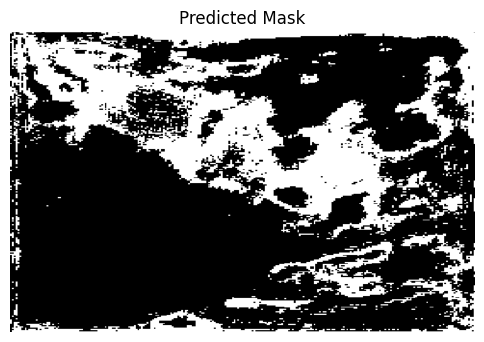

In [28]:
from matplotlib import pyplot as plt

# plot all predictions using matplotlib
preds = inf_job.predictions[0]
plt.figure(figsize=(6, 6))
plt.imshow(preds[0].mask, cmap='gray')
plt.title("Predicted Mask")
plt.axis('off')

In [ ]:
# Open the Datamint dashboard for this project
proj.show()

## Summary: What the Trainer API Automates

The Trainer API automatically handles the full segmentation workflow, including:

- Dataset loading and setup
- Semantic segmentation configuration
- Medical-image augmentation pipelines
- Model creation with a pretrained encoder
- Loss function setup
- Metric configuration
- Lightning trainer setup
- Callbacks, checkpointing, and early stopping
- MLflow experiment tracking
- Test-time evaluation
- Deployment adapter creation

This keeps the training workflow concise while still allowing customization through custom models, transforms, loss functions, and trainer arguments.